NAME: KAMAKHYA KANZADE<br>
PRN: 202401110016<br>
Practical No-05: Image Generation using Pretrained Stable Diffusion
<br>
link: https://colab.research.google.com/drive/154RB-tqaraJUs67YXqRRMYI7xJ-TD50p?usp=sharing

# Text-to-Image with Stable Diffusion (Diffusers)
**Goal:** generate images from text prompts with a pretrained Stable Diffusion model and analyze how
**inference steps**, **guidance scale (CFG)** and **sampling method (scheduler)** affect image quality.

> Runtime → Change runtime type → **T4 GPU** before running.

## 1. Install dependencies

In [ ]:
!pip install -q diffusers transformers accelerate safetensors matplotlib
!pip install -U torchao

## 2. Imports and device setup

In [ ]:
import time, torch, numpy as np
import matplotlib.pyplot as plt
from diffusers import (
    StableDiffusionPipeline,
    PNDMScheduler, DDIMScheduler, LMSDiscreteScheduler,
    EulerDiscreteScheduler, EulerAncestralDiscreteScheduler,
    HeunDiscreteScheduler, DPMSolverMultistepScheduler, UniPCMultistepScheduler,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Device:", device, "| dtype:", dtype)
if device == "cpu":
    print("WARNING: no GPU found. Enable a GPU runtime, CPU will be extremely slow.")

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


Device: cuda | dtype: torch.float16


## 3. Load the pretrained Stable Diffusion pipeline

In [ ]:
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # alt: "CompVis/stable-diffusion-v1-4"

pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=dtype)
pipe = pipe.to(device)
pipe.enable_attention_slicing()          # lowers VRAM usage
print("Default scheduler:", pipe.scheduler.__class__.__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Default scheduler: PNDMScheduler


## 4. Helper functions (seeded generation + image grids)

In [ ]:
def generate(prompt, negative_prompt=None, steps=30, guidance=7.5, seed=42,
             height=512, width=512):
    """Generate one image. Same seed => same starting noise => fair comparisons."""
    gen = torch.Generator(device=device).manual_seed(seed)
    out = pipe(prompt, negative_prompt=negative_prompt,
               num_inference_steps=steps, guidance_scale=guidance,
               height=height, width=width, generator=gen)
    return out.images[0]

def show_grid(images, titles, cols=5, figsize=4, suptitle=None):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols*figsize, rows*figsize))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis("off")
    for ax, img, t in zip(axes, images, titles):
        ax.imshow(img); ax.set_title(t, fontsize=11)
    if suptitle: fig.suptitle(suptitle, fontsize=15)
    plt.tight_layout(); plt.show()

def set_scheduler(name):
    """Swap the sampler while reusing the same pipeline weights."""
    cfg = pipe.scheduler.config
    schedulers = {
        "PNDM":              lambda: PNDMScheduler.from_config(cfg),
        "DDIM":              lambda: DDIMScheduler.from_config(cfg),
        "LMS":               lambda: LMSDiscreteScheduler.from_config(cfg),
        "Euler":             lambda: EulerDiscreteScheduler.from_config(cfg),
        "Euler A":           lambda: EulerAncestralDiscreteScheduler.from_config(cfg),
        "Heun":              lambda: HeunDiscreteScheduler.from_config(cfg),
        "DPM++ 2M":          lambda: DPMSolverMultistepScheduler.from_config(cfg),
        "DPM++ 2M Karras":   lambda: DPMSolverMultistepScheduler.from_config(cfg, use_karras_sigmas=True),
        "UniPC":             lambda: UniPCMultistepScheduler.from_config(cfg),
    }
    pipe.scheduler = schedulers[name]()

## 4b. Inside the pipeline — the four main components
Stable Diffusion is a **latent diffusion model**. A `StableDiffusionPipeline` bundles:

| Component | Role |
|---|---|
| **Tokenizer + Text encoder (CLIP ViT-L/14)** | Converts the prompt into token IDs, then into a 77x768 embedding that *conditions* generation |
| **U-Net** | Predicts the noise present in the latent at timestep *t*, using cross-attention to the text embedding |
| **Scheduler (sampler)** | Defines the noise schedule and the update rule that removes the predicted noise step by step |
| **VAE (encoder/decoder)** | Compresses 512x512x3 images into 64x64x4 latents (8x smaller per side) and decodes latents back to pixels |

In [ ]:
def n_params(m): return sum(p.numel() for p in m.parameters()) / 1e6

print("Tokenizer     :", pipe.tokenizer.__class__.__name__, "| max length:", pipe.tokenizer.model_max_length)
print("Text encoder  :", pipe.text_encoder.__class__.__name__, f"| {n_params(pipe.text_encoder):.0f}M params")
print("U-Net         :", pipe.unet.__class__.__name__,         f"| {n_params(pipe.unet):.0f}M params")
print("VAE           :", pipe.vae.__class__.__name__,          f"| {n_params(pipe.vae):.0f}M params")
print("Scheduler     :", pipe.scheduler.__class__.__name__)
print("Latent channels:", pipe.unet.config.in_channels, "| VAE scaling factor:", pipe.vae.config.scaling_factor)

Tokenizer     : CLIPTokenizer | max length: 77
Text encoder  : CLIPTextModel | 123M params
U-Net         : UNet2DConditionModel | 860M params
VAE           : AutoencoderKL | 84M params
Scheduler     : PNDMScheduler
Latent channels: 4 | VAE scaling factor: 0.18215


### Manual denoising loop (what `pipe(...)` does internally)
Steps: (1) encode prompt and an empty/negative prompt, (2) start from pure Gaussian noise in latent space,
(3) at each timestep the U-Net predicts noise for both conditional and unconditional inputs,
(4) combine them with **classifier-free guidance**: `noise = uncond + g * (cond - uncond)`,
(5) the scheduler removes a bit of noise, (6) the VAE decodes the final latent into an image.

Text embedding shape: (1, 77, 768)
Initial latent shape: (1, 4, 64, 64) (noise)


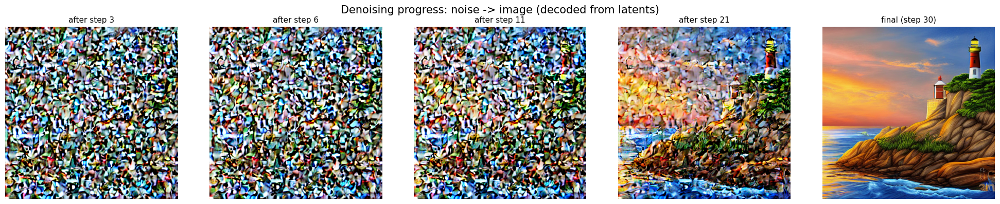

In [ ]:
@torch.no_grad()
def manual_generate(prompt, negative="", steps=30, guidance=7.5, seed=42, snapshot_steps=()):
    set_scheduler("DDIM")
    tok = pipe.tokenizer

    def encode(text):
        ids = tok(text, padding="max_length", max_length=tok.model_max_length,
                  truncation=True, return_tensors="pt").input_ids.to(device)
        return pipe.text_encoder(ids)[0]                      # (1, 77, 768)

    emb = torch.cat([encode(negative), encode(prompt)])       # [uncond, cond]
    print("Text embedding shape:", tuple(emb[1:].shape))

    gen = torch.Generator(device=device).manual_seed(seed)
    latents = torch.randn((1, pipe.unet.config.in_channels, 64, 64),
                          generator=gen, device=device, dtype=dtype)
    print("Initial latent shape:", tuple(latents.shape), "(noise)")

    pipe.scheduler.set_timesteps(steps, device=device)
    latents = latents * pipe.scheduler.init_noise_sigma

    def decode(lat):
        img = pipe.vae.decode(lat / pipe.vae.config.scaling_factor).sample
        return pipe.image_processor.postprocess(img, output_type="pil")[0]

    snaps = []
    for i, t in enumerate(pipe.scheduler.timesteps):
        inp = pipe.scheduler.scale_model_input(torch.cat([latents] * 2), t)
        noise_pred = pipe.unet(inp, t, encoder_hidden_states=emb).sample
        n_uncond, n_cond = noise_pred.chunk(2)
        noise_pred = n_uncond + guidance * (n_cond - n_uncond)          # classifier-free guidance
        latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample
        if i in snapshot_steps:
            snaps.append((i + 1, decode(latents)))
    return decode(latents), snaps

final, snaps = manual_generate("a lighthouse on a cliff at sunset, detailed digital painting",
                               negative="blurry, low quality", steps=30, guidance=7.5,
                               snapshot_steps=(2, 5, 10, 20))
show_grid([s[1] for s in snaps] + [final],
          [f"after step {s[0]}" for s in snaps] + ["final (step 30)"],
          cols=5, suptitle="Denoising progress: noise -> image (decoded from latents)")

## 5. Basic text-to-image generation

  0%|          | 0/30 [00:00<?, ?it/s]

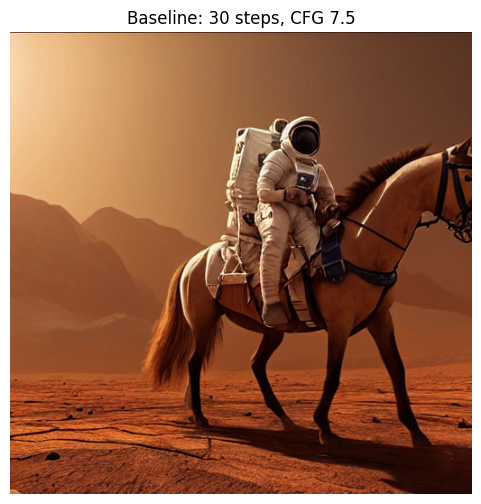

In [ ]:
prompt = "a photorealistic portrait of an astronaut riding a horse on Mars, cinematic lighting, highly detailed"
negative = "blurry, low quality, distorted, extra limbs, watermark"

set_scheduler("DPM++ 2M Karras")
img = generate(prompt, negative, steps=30, guidance=7.5, seed=42)
plt.figure(figsize=(6,6)); plt.imshow(img); plt.axis("off"); plt.title("Baseline: 30 steps, CFG 7.5"); plt.show()

## 5b. Prompt engineering experiments
We test (A) prompt specificity, (B) negative prompts, and (C) style/modifier keywords.
Seed, steps (30), guidance (7.5) and scheduler are fixed so only the prompt changes.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

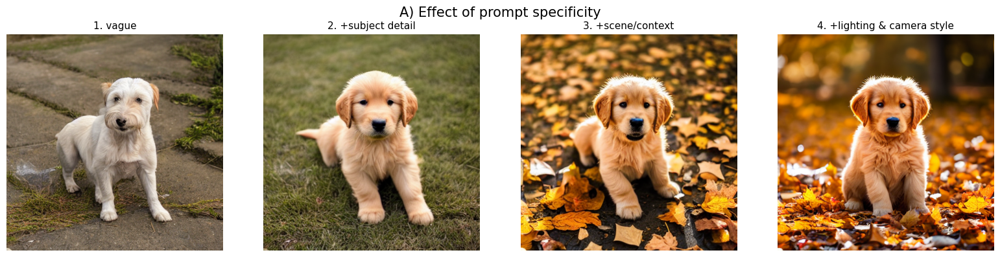

In [ ]:
set_scheduler("DPM++ 2M Karras")

# A) Prompt specificity: vague -> detailed
prompts_A = [
    "a dog",
    "a golden retriever puppy",
    "a golden retriever puppy playing in autumn leaves in a park",
    "a golden retriever puppy playing in autumn leaves in a park, golden hour lighting, "
    "shallow depth of field, 85mm lens, photorealistic, highly detailed, sharp focus",
]
imgs = [generate(p, "blurry, low quality", steps=30, guidance=7.5, seed=42) for p in prompts_A]
show_grid(imgs, ["1. vague", "2. +subject detail", "3. +scene/context", "4. +lighting & camera style"],
          cols=4, suptitle="A) Effect of prompt specificity")

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

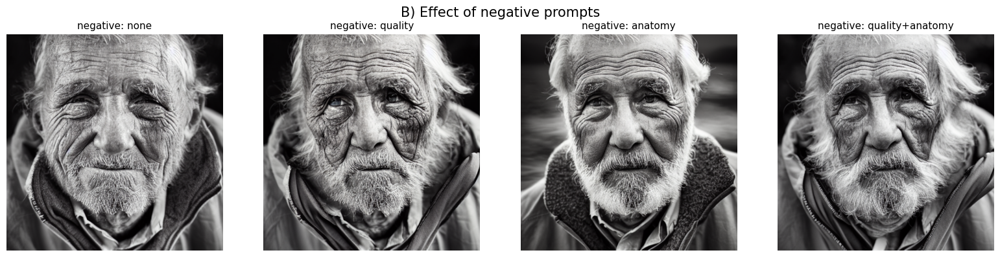

In [ ]:
# B) Negative prompts on/off
base = "portrait of an elderly fisherman, weathered face, studio lighting, photorealistic"
neg_options = {
    "none": None,
    "quality": "blurry, low quality, jpeg artifacts, watermark, text",
    "anatomy": "deformed, disfigured, extra fingers, bad anatomy, asymmetrical eyes",
    "quality+anatomy": "blurry, low quality, jpeg artifacts, watermark, text, deformed, disfigured, bad anatomy",
}
imgs = [generate(base, n, steps=30, guidance=7.5, seed=7) for n in neg_options.values()]
show_grid(imgs, [f"negative: {k}" for k in neg_options], cols=4, suptitle="B) Effect of negative prompts")

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

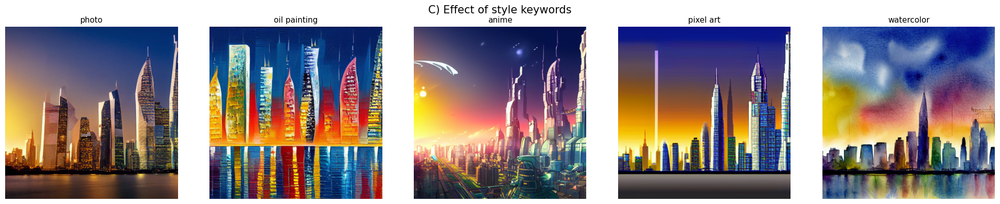

In [ ]:
# C) Style / modifier keywords on the same subject
subject = "a futuristic city skyline at dusk"
styles = ["photograph, 35mm, realistic", "oil painting, impasto brush strokes",
          "anime style, studio ghibli, vibrant", "pixel art, 16-bit", "watercolor, soft washes, pastel"]
imgs = [generate(f"{subject}, {s}", "blurry, low quality", steps=30, guidance=7.5, seed=3) for s in styles]
show_grid(imgs, ["photo", "oil painting", "anime", "pixel art", "watercolor"], cols=5,
          suptitle="C) Effect of style keywords")

**Prompt observations (write your own after running):**
- More specific prompts give more controlled, relevant output; vague prompts leave the model to guess.
- Negative prompts steer the unconditional branch of CFG *away* from unwanted features (blur, bad anatomy).
- Style keywords change texture, color and composition while the subject stays the same.
- CLIP's 77-token limit means words late in a long prompt are truncated; put important terms first.

## 6. Experiment 1 — Effect of inference steps
Fixed: prompt, seed, scheduler (DPM++ 2M Karras), guidance = 7.5. Varied: number of steps.

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

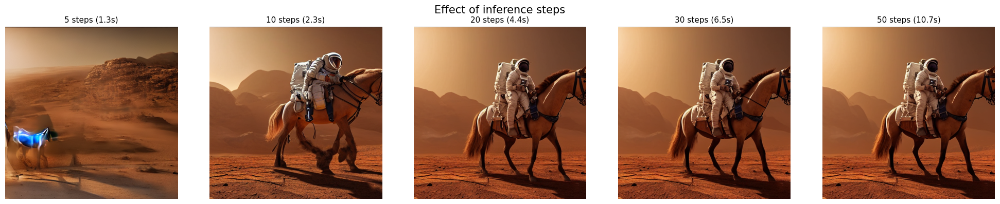

In [ ]:
set_scheduler("DPM++ 2M Karras")
step_values = [5, 10, 20, 30, 50]
imgs, titles, step_times = [], [], []

for s in step_values:
    t0 = time.time()
    im = generate(prompt, negative, steps=s, guidance=7.5, seed=42)
    dt = time.time() - t0
    imgs.append(im); step_times.append(dt)
    titles.append(f"{s} steps ({dt:.1f}s)")

show_grid(imgs, titles, cols=5, suptitle="Effect of inference steps")
imgs_steps = imgs  # keep for CLIP scoring

## 7. Experiment 2 — Effect of guidance scale (CFG)
Fixed: prompt, seed, scheduler, steps = 30. Varied: guidance scale.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

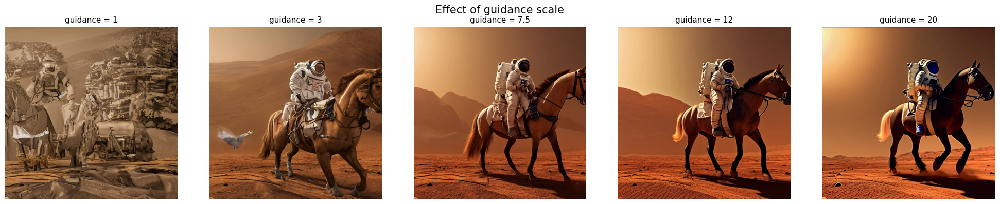

In [ ]:
set_scheduler("DPM++ 2M Karras")
guidance_values = [1, 3, 7.5, 12, 20]
imgs, titles = [], []

for g in guidance_values:
    im = generate(prompt, negative, steps=30, guidance=g, seed=42)
    imgs.append(im); titles.append(f"guidance = {g}")

show_grid(imgs, titles, cols=5, suptitle="Effect of guidance scale")
imgs_guidance = imgs

## 8. Experiment 3 — Effect of sampling method (scheduler)
Fixed: prompt, seed, steps = 25, guidance = 7.5. Varied: scheduler.

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

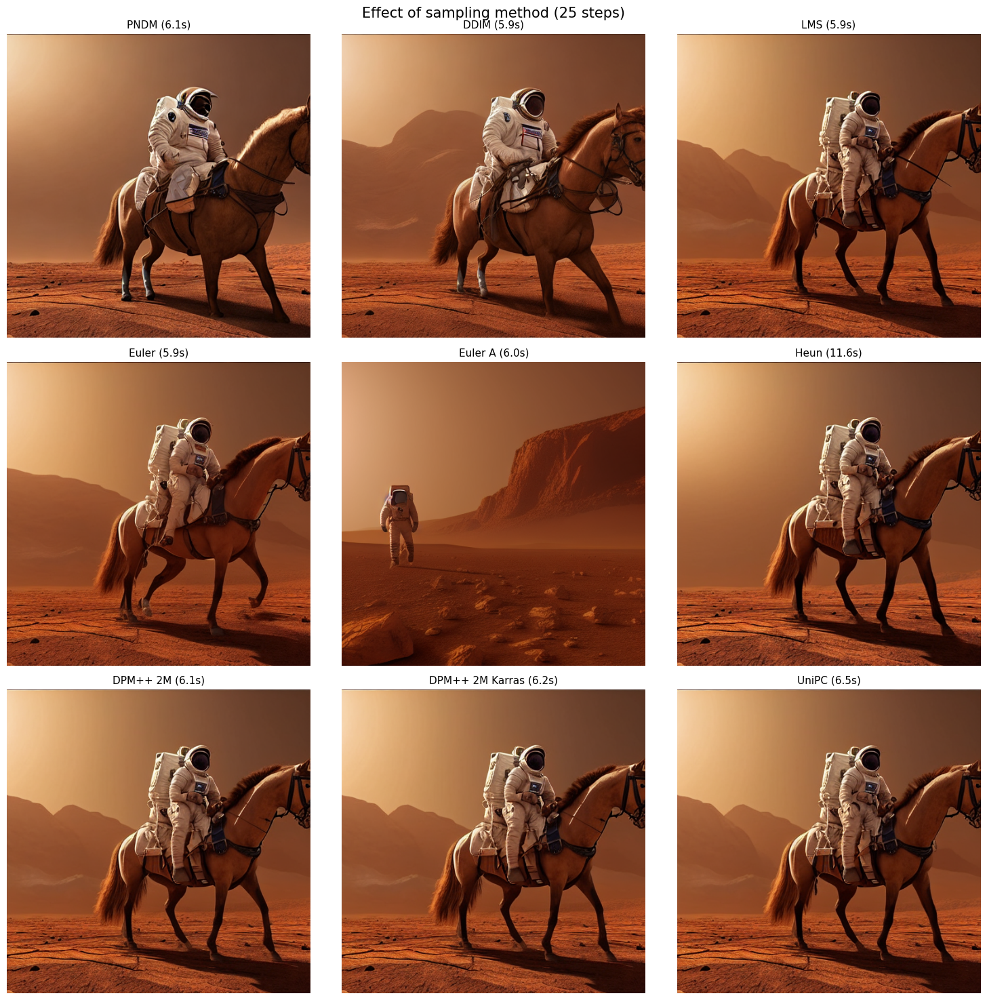

In [ ]:
sampler_names = ["PNDM", "DDIM", "LMS", "Euler", "Euler A",
                 "Heun", "DPM++ 2M", "DPM++ 2M Karras", "UniPC"]
imgs, titles, sampler_times = [], [], {}

for name in sampler_names:
    set_scheduler(name)
    t0 = time.time()
    im = generate(prompt, negative, steps=25, guidance=7.5, seed=42)
    dt = time.time() - t0
    imgs.append(im); sampler_times[name] = dt
    titles.append(f"{name} ({dt:.1f}s)")

show_grid(imgs, titles, cols=3, figsize=5, suptitle="Effect of sampling method (25 steps)")
imgs_samplers = imgs

## 9. Experiment 4 — Samplers vs. steps (convergence)
Shows how quickly each sampler produces a good image with few steps.

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

...

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

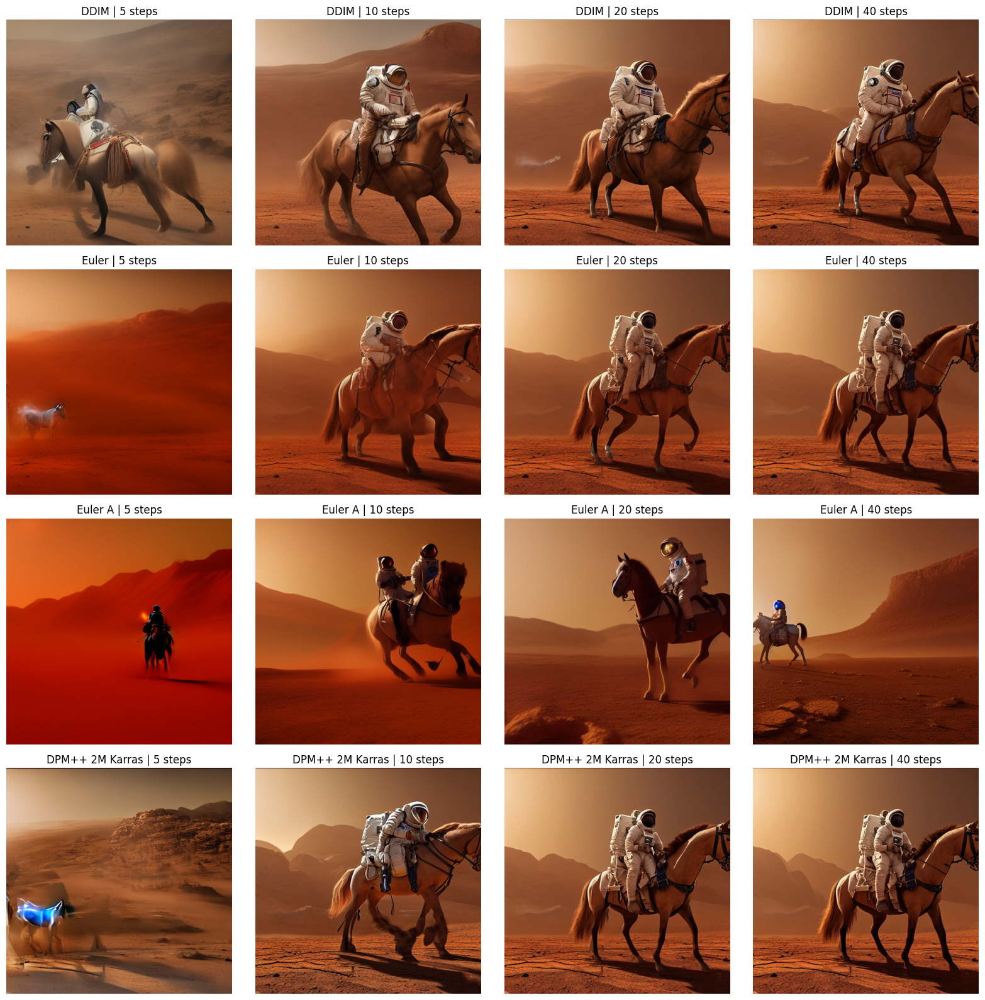

In [ ]:
samplers_sel = ["DDIM", "Euler", "Euler A", "DPM++ 2M Karras"]
steps_sel = [5, 10, 20, 40]

fig, axes = plt.subplots(len(samplers_sel), len(steps_sel), figsize=(4*len(steps_sel), 4*len(samplers_sel)))
for i, sname in enumerate(samplers_sel):
    set_scheduler(sname)
    for j, s in enumerate(steps_sel):
        im = generate(prompt, negative, steps=s, guidance=7.5, seed=42)
        axes[i, j].imshow(im); axes[i, j].axis("off")
        axes[i, j].set_title(f"{sname} | {s} steps")
plt.tight_layout(); plt.show()

## 10. Quantitative evaluation with CLIP score
CLIP similarity between the image and the prompt (higher = better prompt alignment).
This is a proxy metric, so always combine it with visual inspection.

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

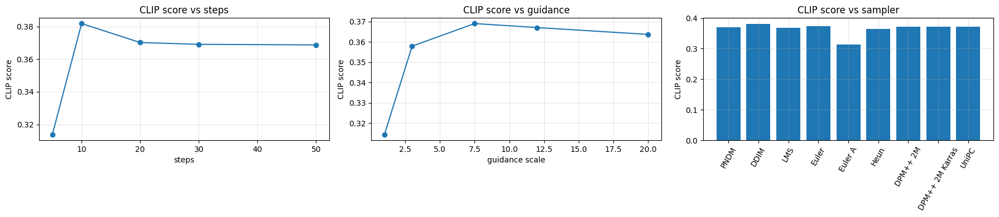

In [ ]:
from transformers import CLIPProcessor, CLIPModel

clip_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_id).to(device)
clip_proc = CLIPProcessor.from_pretrained(clip_id)

@torch.no_grad()
def clip_score(images, text):
    inputs = clip_proc(text=[text]*len(images), images=images,
                       return_tensors="pt", padding=True, truncation=True).to(device)
    out = clip_model(**inputs)
    img_emb = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    txt_emb = out.text_embeds  / out.text_embeds.norm(dim=-1, keepdim=True)
    return (img_emb * txt_emb).sum(-1).cpu().numpy()

scores_steps    = clip_score(imgs_steps, prompt)
scores_guidance = clip_score(imgs_guidance, prompt)
scores_samplers = clip_score(imgs_samplers, prompt)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(step_values, scores_steps, "o-");        ax[0].set_title("CLIP score vs steps");    ax[0].set_xlabel("steps")
ax[1].plot(guidance_values, scores_guidance, "o-"); ax[1].set_title("CLIP score vs guidance"); ax[1].set_xlabel("guidance scale")
ax[2].bar(sampler_names, scores_samplers);          ax[2].set_title("CLIP score vs sampler");  ax[2].tick_params(axis="x", rotation=60)
for a in ax: a.set_ylabel("CLIP score"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 11. Speed vs. quality summary

,steps,time_s,clip_score
0,5,1.31,0.3137
1,10,2.31,0.3818
2,20,4.37,0.3702
3,30,6.48,0.3691
4,50,10.74,0.3687


,sampler,time_s,clip_score
0,PNDM,6.07,0.3708
1,DDIM,5.86,0.3813
2,LMS,5.85,0.3677
3,Euler,5.92,0.3733
4,Euler A,5.98,0.3130
5,Heun,11.62,0.3637
6,DPM++ 2M,6.13,0.3713
7,DPM++ 2M Karras,6.16,0.3713
8,UniPC,6.46,0.3719


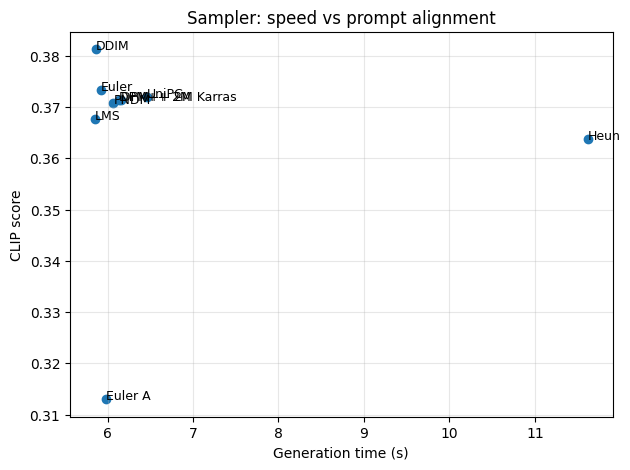

In [ ]:
import pandas as pd

df_steps = pd.DataFrame({"steps": step_values, "time_s": np.round(step_times, 2),
                         "clip_score": np.round(scores_steps, 4)})
df_samp = pd.DataFrame({"sampler": sampler_names,
                        "time_s": [round(sampler_times[n], 2) for n in sampler_names],
                        "clip_score": np.round(scores_samplers, 4)})
display(df_steps); display(df_samp)

plt.figure(figsize=(7,5))
plt.scatter(df_samp.time_s, df_samp.clip_score)
for _, r in df_samp.iterrows(): plt.annotate(r.sampler, (r.time_s, r.clip_score), fontsize=9)
plt.xlabel("Generation time (s)"); plt.ylabel("CLIP score"); plt.title("Sampler: speed vs prompt alignment")
plt.grid(alpha=.3); plt.show()

## 12. Robustness check — repeat with a second prompt and several seeds
Single-seed conclusions can be misleading, so repeat the key comparison across seeds.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

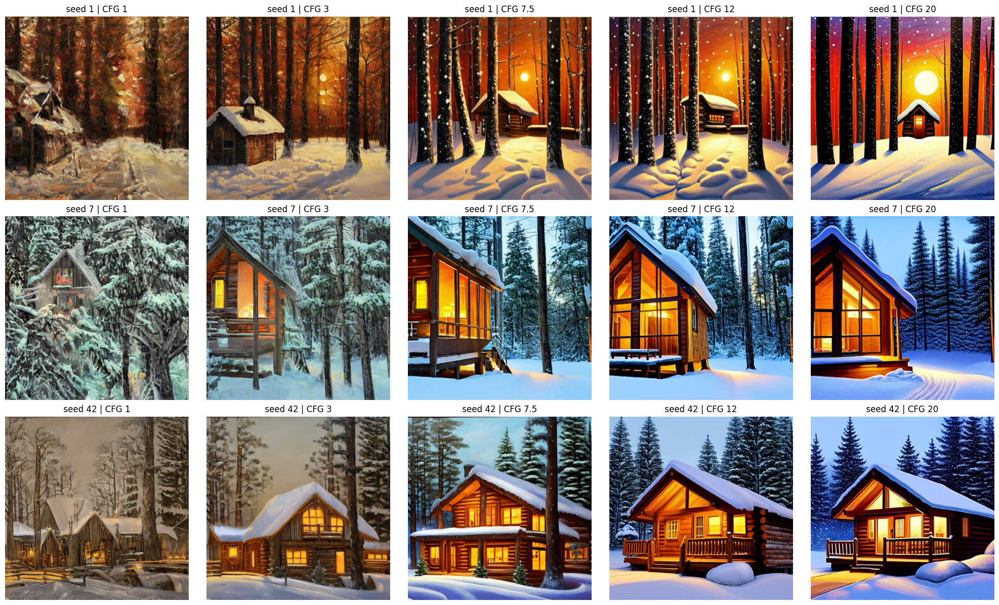

In [ ]:
prompt2 = "a cozy wooden cabin in a snowy forest at night, warm light from windows, oil painting"
seeds = [1, 7, 42]
set_scheduler("DPM++ 2M Karras")

fig, axes = plt.subplots(len(seeds), len(guidance_values), figsize=(4*len(guidance_values), 4*len(seeds)))
for i, sd in enumerate(seeds):
    for j, g in enumerate(guidance_values):
        im = generate(prompt2, negative, steps=30, guidance=g, seed=sd)
        axes[i, j].imshow(im); axes[i, j].axis("off"); axes[i, j].set_title(f"seed {sd} | CFG {g}")
plt.tight_layout(); plt.show()